In [13]:
import pandas as pd

df = pd.read_csv('Formula1_Pitstop_Data_1950-2024_all_rounds.csv')
df = df.dropna(subset=['AvgPitStopTime']).reset_index(drop=True)


In [14]:
print("Observasjoner, kolonner:", df.shape)
print(df[['Season','Round','Laps','Position','TotalPitStops','AvgPitStopTime']].describe())
for col in ['Circuit','Driver','Constructor']:
    print(col, df[col].value_counts().head())


Observasjoner, kolonner: (5575, 10)
            Season        Round         Laps     Position  TotalPitStops  \
count  5575.000000  5575.000000  5575.000000  5575.000000    5575.000000   
mean   2017.503318    10.778834    57.012377    10.387265       2.039462   
std       4.143239     5.994590    12.300362     5.819940       0.988208   
min    2011.000000     1.000000     0.000000     1.000000       1.000000   
25%    2014.000000     6.000000    52.000000     5.000000       1.000000   
50%    2017.000000    11.000000    56.000000    10.000000       2.000000   
75%    2021.000000    16.000000    66.000000    15.000000       3.000000   
max    2024.000000    24.000000    87.000000    24.000000       7.000000   

       AvgPitStopTime  
count     5575.000000  
mean        71.895647  
std        205.507734  
min         16.549000  
25%         22.163500  
50%         23.902000  
75%         27.997750  
max       3055.732000  
Circuit Circuit
Silverstone Circuit               288
Circuit d

In [15]:
print(df.isna().sum())
# Sjekk 0

Season            0
Round             0
Circuit           0
Driver            0
Constructor       0
Laps              0
Position          0
TotalPitStops     0
AvgPitStopTime    0
PitStops          0
dtype: int64


In [16]:
# Kontinuerlige features
print(df[['Season','Round','Laps','Position','TotalPitStops','AvgPitStopTime']].describe())

# Kategoriske (topp 5)
for col in ['Circuit','Driver','Constructor']:
    print(col, df[col].value_counts().head())


            Season        Round         Laps     Position  TotalPitStops  \
count  5575.000000  5575.000000  5575.000000  5575.000000    5575.000000   
mean   2017.503318    10.778834    57.012377    10.387265       2.039462   
std       4.143239     5.994590    12.300362     5.819940       0.988208   
min    2011.000000     1.000000     0.000000     1.000000       1.000000   
25%    2014.000000     6.000000    52.000000     5.000000       1.000000   
50%    2017.000000    11.000000    56.000000    10.000000       2.000000   
75%    2021.000000    16.000000    66.000000    15.000000       3.000000   
max    2024.000000    24.000000    87.000000    24.000000       7.000000   

       AvgPitStopTime  
count     5575.000000  
mean        71.895647  
std        205.507734  
min         16.549000  
25%         22.163500  
50%         23.902000  
75%         27.997750  
max       3055.732000  
Circuit Circuit
Silverstone Circuit               288
Circuit de Barcelona-Catalunya    283
Hungaro

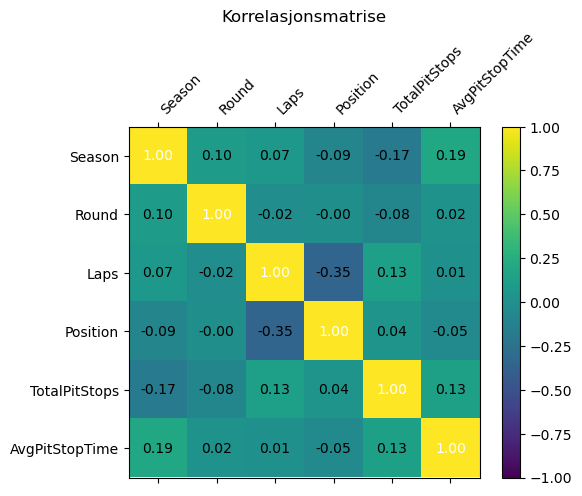

Korrelasjon mot target:
 Position        -0.053
Laps             0.007
Round            0.022
TotalPitStops    0.134
Season           0.191
Name: AvgPitStopTime, dtype: float64


In [17]:
import numpy as np
import matplotlib.pyplot as plt

num = ['Season','Round','Laps','Position','TotalPitStops','AvgPitStopTime']
corr = df[num].corr().round(3)

fig, ax = plt.subplots(figsize=(6,5))
cax = ax.matshow(corr, vmin=-1, vmax=1)
fig.colorbar(cax)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha='left')
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for (i,j),val in np.ndenumerate(corr.values):
    ax.text(j,i,f"{val:.2f}",ha='center',va='center',
            color='white' if abs(val)>0.5 else 'black')
plt.title('Korrelasjonsmatrise'); plt.tight_layout(); plt.show()

print("Korrelasjon mot target:\n", corr['AvgPitStopTime'].drop('AvgPitStopTime').sort_values())


In [18]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Split
X = df[['Season','Round','Laps','Position','TotalPitStops']]
y = df['AvgPitStopTime']
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test,   y_val,   y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

# Lineær
pipe_lr = Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())])

# Random Forest
param_rf = {'n_estimators':[100,200], 'max_depth':[None,10], 'min_samples_leaf':[1,3]}
rf_cv = GridSearchCV(RandomForestRegressor(random_state=42), param_rf,
                     cv=3, scoring='neg_mean_squared_error', n_jobs=-1)

# SVR
pipe_svr = Pipeline([('scaler', StandardScaler()), ('svr', SVR())])
param_svr = {'svr__C':[0.1,1], 'svr__epsilon':[0.1,0.5], 'svr__kernel':['rbf','linear']}
svr_cv = GridSearchCV(pipe_svr, param_svr,
                      cv=3, scoring='neg_mean_squared_error', n_jobs=-1)

# T
pipe_lr.fit(X_train, y_train)
rf_cv.fit(X_train, y_train)
svr_cv.fit(X_train, y_train)
best_lr  = pipe_lr
best_rf  = rf_cv.best_estimator_
best_svr = svr_cv.best_estimator_

# Tabell
for name, model in [('LinearRegression', best_lr),
                    ('RandomForest',    best_rf),
                    ('SVR',             best_svr)]:
    mse_val  = mean_squared_error(y_val,  model.predict(X_val))
    mse_test = mean_squared_error(y_test, model.predict(X_test))
    r2_val   = r2_score(y_val,  model.predict(X_val))
    r2_test  = r2_score(y_test, model.predict(X_test))
    print(f"{name:15s}| Val MSE: {mse_val:.2f}, Test MSE: {mse_test:.2f} | Val R²: {r2_val:.3f}, Test R²: {r2_test:.3f}")


LinearRegression| Val MSE: 36821.59, Test MSE: 50779.88 | Val R²: 0.074, Test R²: 0.062
RandomForest   | Val MSE: 8979.07, Test MSE: 12327.88 | Val R²: 0.774, Test R²: 0.772
SVR            | Val MSE: 41780.11, Test MSE: 56933.29 | Val R²: -0.050, Test R²: -0.051


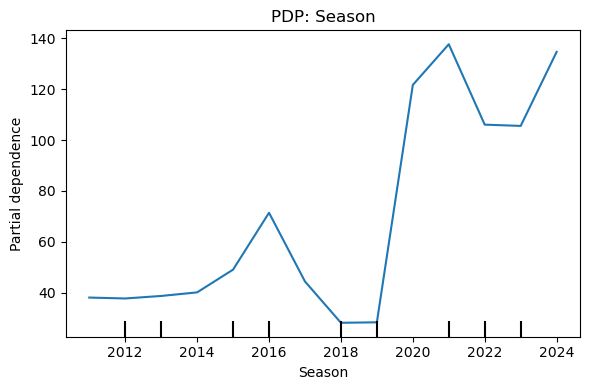

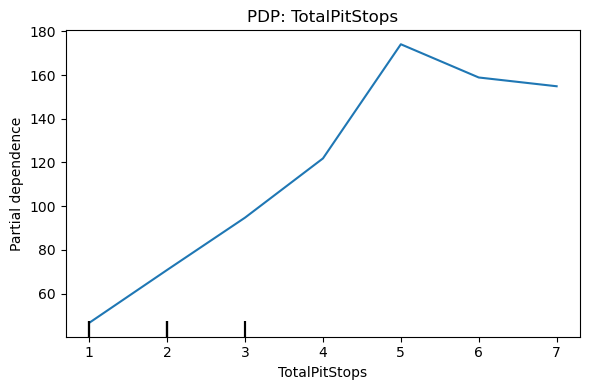

In [19]:
from sklearn.inspection import PartialDependenceDisplay

for feat in ['Season','TotalPitStops']:
    fig, ax = plt.subplots(figsize=(6,4))
    PartialDependenceDisplay.from_estimator(best_rf, X_train, [feat], ax=ax)
    ax.set_title(f'PDP: {feat}')
    plt.tight_layout(); plt.show()


In [20]:
from sklearn.inspection import partial_dependence

pdp2 = partial_dependence(best_rf, X_train, ['Season','TotalPitStops'], grid_resolution=20)['average'][0]
pd1  = partial_dependence(best_rf, X_train, ['Season'],        grid_resolution=20)['average'][0]
pd2  = partial_dependence(best_rf, X_train, ['TotalPitStops'], grid_resolution=20)['average'][0]
F1 = np.repeat(pd1[:,None], len(pd2), axis=1)
F2 = np.repeat(pd2[None,:], len(pd1), axis=0)
H  = np.sqrt(np.mean((pdp2 - F1 - F2)**2) / np.mean(pdp2**2))
print(f"H-stat (Season×TotalPitStops): {H:.3f}")


H-stat (Season×TotalPitStops): 0.630


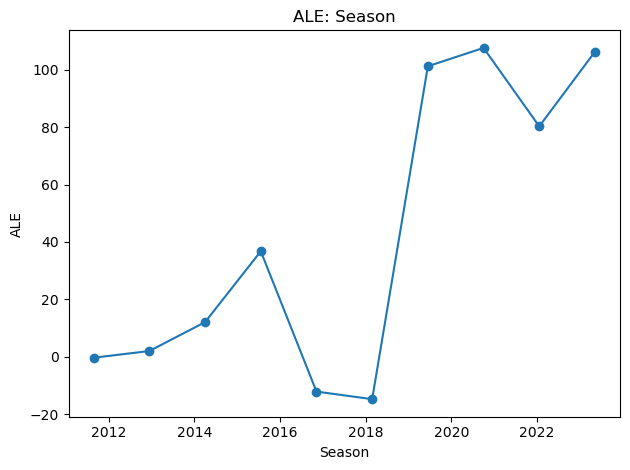

In [21]:
bins     = np.linspace(X_train['Season'].min(), X_train['Season'].max(), 11)
centers  = (bins[:-1] + bins[1:]) / 2
ale_vals = []
for i in range(len(bins)-1):
    df_low  = X_train.copy(); df_low['Season'] = bins[i]
    df_high = X_train.copy(); df_high['Season'] = bins[i+1]
    ale_vals.append(np.mean(best_rf.predict(df_high) - best_rf.predict(df_low)))
ale_cum = np.cumsum(ale_vals)
plt.plot(centers, ale_cum, marker='o')
plt.title('ALE: Season'); plt.xlabel('Season'); plt.ylabel('ALE'); plt.tight_layout(); plt.show()


PFI:
 Season           0.998620
Laps             0.786364
Round            0.415030
TotalPitStops    0.303461
Position         0.044651
dtype: float64


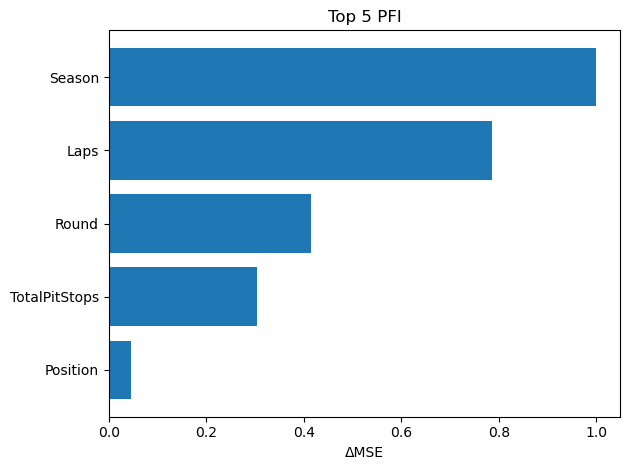

In [22]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_rf, X_test, y_test, n_repeats=15, random_state=42, n_jobs=-1)
imp  = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("PFI:\n", imp)
plt.barh(imp.head(5)[::-1].index, imp.head(5)[::-1].values)
plt.title('Top 5 PFI'); plt.xlabel('ΔMSE'); plt.tight_layout(); plt.show()


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

y_rf = best_rf.predict(X_train)
sur  = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_rf)
print(f"Surrogatmodell R²: {r2_score(y_rf, sur.predict(X_train)):.3f}")


Surrogatmodell R²: 0.173


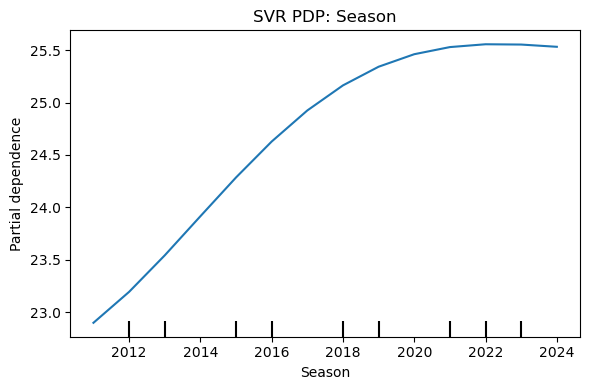

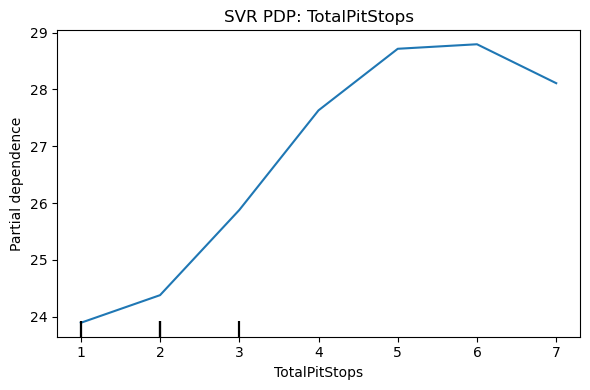

SVR Permutation FI:
 TotalPitStops    0.003121
Season           0.002673
Laps             0.001373
Round            0.000584
Position         0.000261
dtype: float64


In [24]:
# PDP for SVR
for feat in ['Season','TotalPitStops']:
    fig, ax = plt.subplots(figsize=(6,4))
    PartialDependenceDisplay.from_estimator(best_svr, X_train, [feat], ax=ax)
    ax.set_title(f'SVR PDP: {feat}')
    plt.tight_layout(); plt.show()

# Permutation FI for SVR
perm_s = permutation_importance(best_svr, X_test, y_test, n_repeats=15, random_state=42, n_jobs=-1)
imp_s  = pd.Series(perm_s.importances_mean, index=X.columns).sort_values(ascending=False)
print("SVR Permutation FI:\n", imp_s)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/_bunch.py:35: FutureWarning: Key: 'values', is deprecated in 1.3 and will be removed in 1.5. Please use 'grid_values' instead.
  warnings.warn(


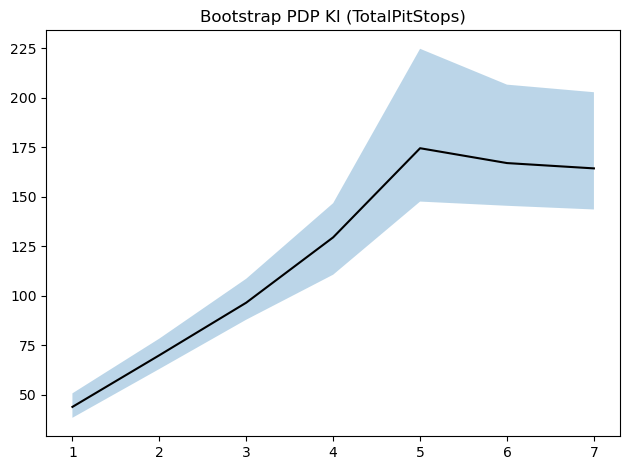

PFI med 90% KI:
                    mean        5%       95%
Season         0.998620  0.902250  1.149657
Laps           0.786364  0.671994  0.916838
Round          0.415030  0.280061  0.508146
TotalPitStops  0.303461  0.225800  0.414240
Position       0.044651  0.019663  0.064613


In [27]:
from sklearn.utils import resample

# PDP‐bootstrap TotalPitStops
B = 30
grid_pdp = None
pdp_boot = []
for b in range(B):
    idx  = resample(X_train.index, replace=True, n_samples=len(X_train))
    rf_b = RandomForestRegressor(**best_rf.get_params()).fit(X_train.loc[idx], y_train.loc[idx])
    pdpb = partial_dependence(rf_b, X_train, ['TotalPitStops'], grid_resolution=20)
    if grid_pdp is None: grid_pdp = pdpb['values'][0]
    pdp_boot.append(pdpb['average'][0])
arr = np.vstack(pdp_boot)
low, high = np.percentile(arr, [5,95], axis=0)
meanp     = arr.mean(axis=0)
plt.fill_between(grid_pdp, low, high, alpha=0.3)
plt.plot(grid_pdp, meanp, color='black')
plt.title('Bootstrap PDP KI (TotalPitStops)'); plt.tight_layout(); plt.show()

# PFI‐bootstrap KI
perm_bs = []
for b in range(B):
    samp = resample(X_test.index, replace=True, n_samples=len(X_test))
    pi   = permutation_importance(best_rf, X_test.loc[samp], y_test.loc[samp], n_repeats=10, random_state=b)
    perm_bs.append(pi.importances_mean)
perm_arr = np.vstack(perm_bs)
ci_low   = np.percentile(perm_arr,5,axis=0)
ci_hi    = np.percentile(perm_arr,95,axis=0)
pfi_df   = pd.DataFrame({'mean':imp,'5%':ci_low,'95%':ci_hi}, index=X.columns).sort_values('mean',ascending=False)
print("PFI med 90% KI:\n", pfi_df.head())


In [26]:
from sklearn.linear_model import LinearRegression
from scipy import stats

x    = grid_pdp.reshape(-1,1)
y_p  = meanp

# Lineær
lr   = LinearRegression().fit(x, y_p)
rss1 = np.sum((y_p - lr.predict(x))**2)

# Kvadratisk
X2   = np.hstack([x, x**2])
lr2  = LinearRegression().fit(X2, y_p)
rss2 = np.sum((y_p - lr2.predict(X2))**2)

df1, df2 = 1, len(x)-2
F    = ((rss1-rss2)/df1)/(rss2/df2)
p    = 1 - stats.f.cdf(F, df1, df2)
print(f"F={F:.2f}, p-verdi={p:.3f}")


F=5.81, p-verdi=0.061
